# Sneha Singh
## DATA 266 — Homework 9
Latent Diffusion on FashionMNIST

This notebook loads a pretrained Stable Diffusion VAE, checks reconstruction on FashionMNIST, runs forward diffusion in that latent space, trains a conditional U-Net to predict noise, and samples with classifier-free guidance.


In [1]:
# Step 0: Libraries & Student Parameters
import math
import os
import random
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image
from diffusers import AutoencoderKL

# last 4 of my SJSUid - 0670; use the same seed as the earlier homework
SEED = 670
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
T = 1000
BETA_START = 1e-4
BETA_END = 0.02
BATCH_SIZE = 128
EPOCHS = 50
LR = 2e-5
IMG_SIZE = 128
SCALE = 0.18215
NULL_LABEL = 10
LABEL_DROP = 0.1
GUIDANCE = 3.0
VAE_NAME = 'stabilityai/sd-vae-ft-mse'

CLASS_NAMES = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot',
]

os.makedirs('figures', exist_ok=True)
os.makedirs('checkpoints', exist_ok=True)
os.makedirs('outputs', exist_ok=True)
print('torch', torch.__version__)
print('device:', device)


torch 2.14.0
device: mps


This assignment said follow the same step 0 as assignment 1. I did not train a second hyperparameter network. HP_ID is reported only. The two models in this homework are the pretrained VAE and the U-Net I train below.

SID4 = 0670, SEED = 670, SLICE = 670, HP_ID = 4, CLS_A = 0, CLS_B = 5.


## 1. VAE compression

I load `stabilityai/sd-vae-ft-mse` and I do not train it. FashionMNIST is 28×28 and grayscale. This VAE expects 3 channels and a size that divides by 8, and it downsamples by 8. I resize each image to 128×128 and repeat the gray channel three times, so the latent is 4×16×16. The U-Net self-attention sits on that 16×16 map.

Diffusion uses the scaled latent, `z * 0.18215`. The decoder was trained on the unscaled latent, so I divide by 0.18215 before decoding. The MSE below is on the test set, against the 128×128 tensors that went into the encoder, in [-1, 1]. I use the posterior mean so an image has one latent.


vae scaling_factor: 0.18215
encoded 1600/60000
encoded 3200/60000
encoded 4800/60000
encoded 6400/60000
encoded 8000/60000
encoded 9600/60000
encoded 11200/60000
encoded 12800/60000
encoded 14400/60000
encoded 16000/60000
encoded 17600/60000
encoded 19200/60000
encoded 20800/60000
encoded 22400/60000
encoded 24000/60000
encoded 25600/60000
encoded 27200/60000
encoded 28800/60000
encoded 30400/60000
encoded 32000/60000
encoded 33600/60000
encoded 35200/60000
encoded 36800/60000
encoded 38400/60000
encoded 40000/60000
encoded 41600/60000
encoded 43200/60000
encoded 44800/60000
encoded 46400/60000
encoded 48000/60000
encoded 49600/60000
encoded 51200/60000
encoded 52800/60000
encoded 54400/60000
encoded 56000/60000
encoded 57600/60000
encoded 59200/60000
encoded 60000/60000
train latent shape: (60000, 4, 16, 16)
reconstruction 1600/10000
reconstruction 3200/10000
reconstruction 4800/10000
reconstruction 6400/10000
reconstruction 8000/10000
reconstruction 9600/10000
reconstruction 10000/10

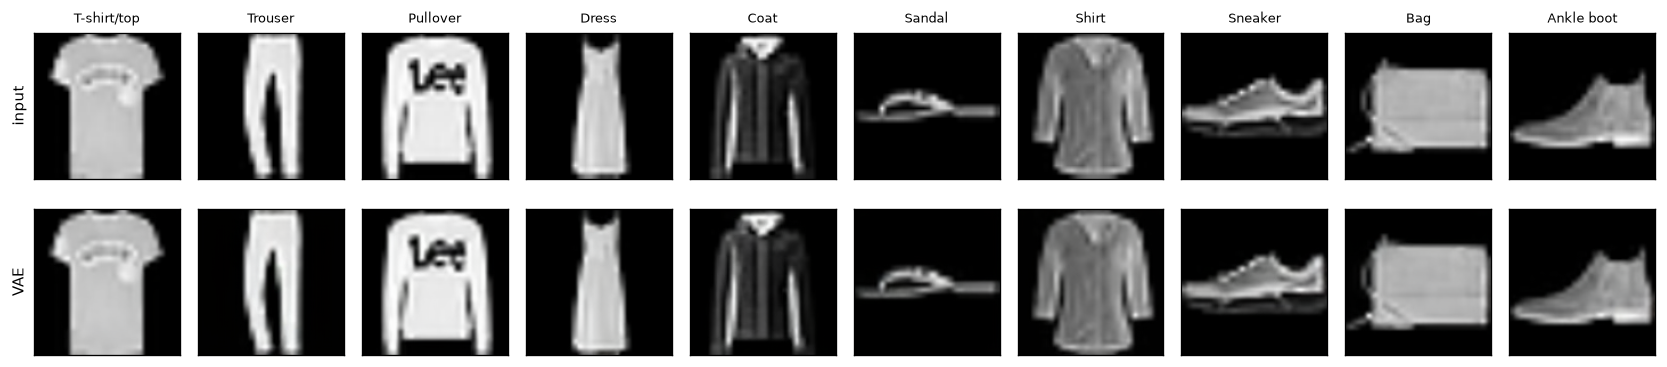

In [2]:
# load the pretrained VAE and freeze it
vae = AutoencoderKL.from_pretrained(VAE_NAME).to(device).eval()
vae.requires_grad_(False)
print('vae scaling_factor:', float(vae.config.scaling_factor))

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x.repeat(3, 1, 1)),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])
train_data = datasets.FashionMNIST('./data', train=True, download=True, transform=transform)
test_data = datasets.FashionMNIST('./data', train=False, download=True, transform=transform)

def encode_split(dataset, cache_path):
    if os.path.exists(cache_path):
        saved = torch.load(cache_path, map_location='cpu', weights_only=False)
        print('loaded', cache_path, tuple(saved['z'].shape))
        return saved['z'], saved['y']
    loader = DataLoader(dataset, batch_size=16, shuffle=False, num_workers=0)
    latents, labels = [], []
    seen = 0
    with torch.no_grad():
        for x, y in loader:
            z = vae.encode(x.to(device)).latent_dist.mean * SCALE
            latents.append(z.cpu())
            labels.append(y)
            seen += x.shape[0]
            if seen % 1600 == 0 or seen == len(dataset):
                print(f'encoded {seen}/{len(dataset)}')
    z_all = torch.cat(latents)
    y_all = torch.cat(labels)
    torch.save({'z': z_all, 'y': y_all}, cache_path)
    return z_all, y_all

z_train, y_train = encode_split(train_data, 'checkpoints/train_latents.pt')
print('train latent shape:', tuple(z_train.shape))

# one test image per class, plus MSE on all 10,000 test images
recon_cache = 'checkpoints/recon_check.pt'
if os.path.exists(recon_cache):
    saved = torch.load(recon_cache, map_location='cpu', weights_only=False)
    test_mse = saved['test_mse']
    picked_x = saved['picked_x']
    picked_r = saved['picked_r']
    print('loaded reconstruction check')
else:
    test_loader = DataLoader(test_data, batch_size=16, shuffle=False, num_workers=0)
    picked_x, picked_r = {}, {}
    total = 0.0
    count = 0
    seen = 0
    with torch.no_grad():
        for x, y in test_loader:
            x = x.to(device)
            z = vae.encode(x).latent_dist.mean * SCALE
            recon = vae.decode(z / SCALE).sample
            total += F.mse_loss(recon, x, reduction='sum').item()
            count += x.numel()
            for i in range(x.shape[0]):
                cls = int(y[i])
                if cls not in picked_x:
                    picked_x[cls] = ((x[i].detach().cpu() + 1) * 0.5).clamp(0, 1)
                    picked_r[cls] = ((recon[i].detach().cpu() + 1) * 0.5).clamp(0, 1)
            seen += x.shape[0]
            if seen % 1600 == 0 or seen == len(test_data):
                print(f'reconstruction {seen}/{len(test_data)}')
    test_mse = total / count
    torch.save({'test_mse': test_mse, 'picked_x': picked_x, 'picked_r': picked_r}, recon_cache)

print(f'test reconstruction MSE: {test_mse:.6f}')

fig, axes = plt.subplots(2, 10, figsize=(14, 3.4))
for i in range(10):
    axes[0, i].imshow(picked_x[i].permute(1, 2, 0).numpy())
    axes[1, i].imshow(picked_r[i].permute(1, 2, 0).numpy())
    axes[0, i].set_title(CLASS_NAMES[i], fontsize=8)
    for row in range(2):
        axes[row, i].set_xticks([])
        axes[row, i].set_yticks([])
axes[0, 0].set_ylabel('input', fontsize=9)
axes[1, 0].set_ylabel('VAE', fontsize=9)
plt.tight_layout()
plt.savefig('figures/reconstructions.png', dpi=150)
plt.show()


## 2. Forward diffusion in latent space

T = 1000. β increases linearly from 1e-4 to 0.02. The closed form is the usual one, applied to the scaled latent z0:

z_t = sqrt(ᾱ_t) z0 + sqrt(1 − ᾱ_t) ε, with ε ~ N(0, I).

The schedule has indices 0..999, so there is no index 1000. In the figure, t=0 is the clean latent. t=200, 500, and 800 use those indices. t=1000 is the last step, index 999. I decode each latent so the figure is an image, not a 4×16×16 tensor.


t=200 index=200 alpha_bar=6.563466e-01
t=500 index=500 alpha_bar=7.779661e-02
t=800 index=800 alpha_bar=1.507520e-03
t=1000 index=999 alpha_bar=4.035827e-05


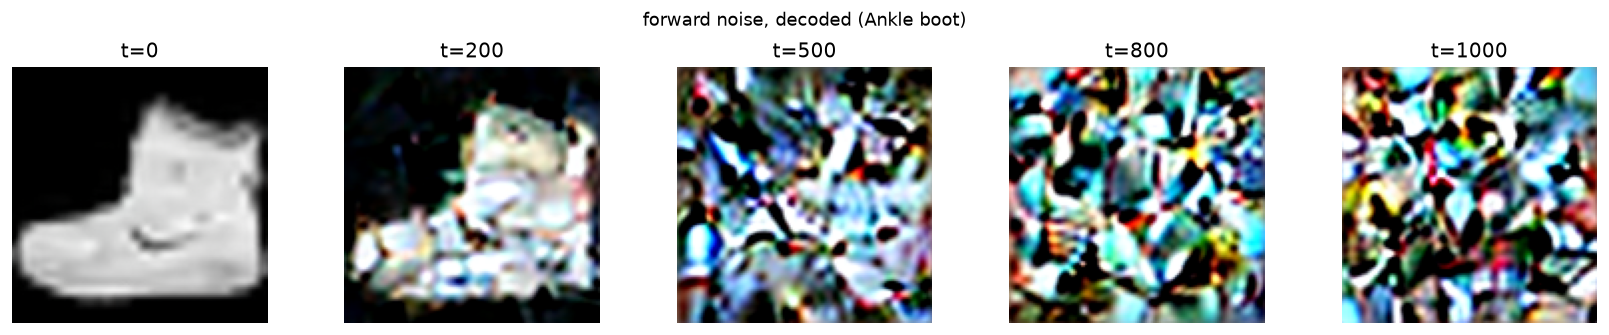

In [3]:
# forward diffusion schedule on the scaled latent
betas = torch.linspace(BETA_START, BETA_END, T, device=device)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)
alpha_bars_prev = F.pad(alpha_bars[:-1], (1, 0), value=1.0)
sqrt_alpha_bars = torch.sqrt(alpha_bars)
sqrt_one_minus_alpha_bars = torch.sqrt(1.0 - alpha_bars)
posterior_variance = betas * (1.0 - alpha_bars_prev) / (1.0 - alpha_bars)

def extract(values, t, x_shape):
    out = values.gather(0, t)
    return out.reshape(t.shape[0], *((1,) * (len(x_shape) - 1)))

def q_sample(z0, t, noise=None):
    if noise is None:
        noise = torch.randn_like(z0)
    return (extract(sqrt_alpha_bars, t, z0.shape) * z0
            + extract(sqrt_one_minus_alpha_bars, t, z0.shape) * noise), noise

for label, index in [('t=200', 200), ('t=500', 500), ('t=800', 800), ('t=1000', 999)]:
    print(f'{label} index={index} alpha_bar={alpha_bars[index].item():.6e}')

# decode one training latent at the requested timesteps
z0 = z_train[0:1].to(device)
image_label = int(y_train[0])
show_steps = [0, 200, 500, 800, 1000]
fig, axes = plt.subplots(1, len(show_steps), figsize=(14, 2.8))
with torch.no_grad():
    for ax, step in zip(axes, show_steps):
        if step == 0:
            zt = z0
        else:
            index = 999 if step == 1000 else step
            t = torch.tensor([index], device=device)
            zt, _ = q_sample(z0, t)
        decoded = vae.decode(zt / SCALE).sample
        image = ((decoded[0].detach().cpu() + 1) * 0.5).clamp(0, 1)
        ax.imshow(image.permute(1, 2, 0).numpy())
        ax.set_title(f't={step}')
        ax.axis('off')
plt.suptitle(f'forward noise, decoded ({CLASS_NAMES[image_label]})', fontsize=11)
plt.tight_layout()
plt.savefig('figures/forward_diffusion.png', dpi=150)
plt.show()

# training does not need the VAE on the GPU
vae.to('cpu')
if device.type == 'mps':
    torch.mps.empty_cache()


## 3. Conditional U-Net

The denoiser takes the 4×16×16 latent. Base channels are 64 and the multipliers are (1, 2, 4), so the maps are 16×16 (64 channels), 8×8 (128), and 4×4 (256). Each level has two residual blocks, GroupNorm, and SiLU, and the U-Net keeps the skip connections. Self-attention is on the 16×16 maps and again at the 4×4 bottleneck.

Time is a sinusoidal embedding through an MLP. There are 10 class labels plus one null label (index 10). I add the label embedding to the time embedding. During training I replace the label with the null label with probability 0.1.


In [4]:
# sinusoidal time embedding, residual block, and self-attention
def sinusoidal_embedding(t, dim):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device, dtype=torch.float32) / half)
    args = t.float()[:, None] * freqs[None, :]
    return torch.cat([torch.sin(args), torch.cos(args)], dim=-1)

class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, emb_dim, groups=32):
        super().__init__()
        self.norm1 = nn.GroupNorm(groups, in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.norm2 = nn.GroupNorm(groups, out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.emb_proj = nn.Linear(emb_dim, out_ch)
        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.emb_proj(F.silu(emb))[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)

class SelfAttention(nn.Module):
    def __init__(self, channels, groups=32):
        super().__init__()
        self.norm = nn.GroupNorm(groups, channels)
        self.qkv = nn.Conv2d(channels, channels * 3, 1)
        self.proj = nn.Conv2d(channels, channels, 1)

    def forward(self, x):
        b, c, h, w = x.shape
        q, k, v = self.qkv(self.norm(x)).reshape(b, 3, c, h * w).unbind(1)
        attn = torch.softmax(torch.einsum('bcn,bcm->bnm', q * (c ** -0.5), k), dim=-1)
        out = torch.einsum('bnm,bcm->bcn', attn, v).reshape(b, c, h, w)
        return x + self.proj(out)

class Downsample(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv = nn.Conv2d(channels, channels, 3, stride=2, padding=1)

    def forward(self, x):
        return self.conv(x)

class Upsample(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv = nn.Conv2d(channels, channels, 3, padding=1)

    def forward(self, x):
        x = F.interpolate(x, scale_factor=2, mode='nearest')
        return self.conv(x)

class LatentUNet(nn.Module):
    def __init__(self, in_channels=4, base=64, mults=(1, 2, 4), num_classes=11):
        super().__init__()
        self.time_dim = base * 4
        self.time_mlp = nn.Sequential(
            nn.Linear(self.time_dim, self.time_dim),
            nn.SiLU(),
            nn.Linear(self.time_dim, self.time_dim),
        )
        self.label_emb = nn.Embedding(num_classes, self.time_dim)
        self.conv_in = nn.Conv2d(in_channels, base, 3, padding=1)

        channels = [base * m for m in mults]
        self.down_blocks = nn.ModuleList()
        self.downsamples = nn.ModuleList()
        ch = base
        skip_channels = []
        for i, out_ch in enumerate(channels):
            blocks = nn.ModuleList()
            for _ in range(2):
                blocks.append(ResBlock(ch, out_ch, self.time_dim))
                ch = out_ch
                skip_channels.append(ch)
            # self-attention on the 16x16 map, which is the first level
            if i == 0:
                blocks.append(SelfAttention(ch))
            self.down_blocks.append(blocks)
            if i < len(channels) - 1:
                self.downsamples.append(Downsample(ch))

        self.mid1 = ResBlock(ch, ch, self.time_dim)
        self.mid_attn = SelfAttention(ch)
        self.mid2 = ResBlock(ch, ch, self.time_dim)

        self.up_blocks = nn.ModuleList()
        self.upsamples = nn.ModuleList()
        for i, out_ch in enumerate(reversed(channels)):
            blocks = nn.ModuleList()
            for _ in range(2):
                skip_ch = skip_channels.pop()
                blocks.append(ResBlock(ch + skip_ch, out_ch, self.time_dim))
                ch = out_ch
            if i == len(channels) - 1:
                blocks.append(SelfAttention(ch))
            self.up_blocks.append(blocks)
            if i < len(channels) - 1:
                self.upsamples.append(Upsample(ch))

        self.out_norm = nn.GroupNorm(32, ch)
        self.out_conv = nn.Conv2d(ch, in_channels, 3, padding=1)

    def forward(self, x, t, y):
        # label embedding added to the time embedding
        emb = self.time_mlp(sinusoidal_embedding(t, self.time_dim)) + self.label_emb(y)
        h = self.conv_in(x)
        skips = []
        for i, blocks in enumerate(self.down_blocks):
            for block in blocks:
                if isinstance(block, ResBlock):
                    h = block(h, emb)
                    skips.append(h)
                else:
                    h = block(h)
            if i < len(self.downsamples):
                h = self.downsamples[i](h)
        h = self.mid1(h, emb)
        h = self.mid_attn(h)
        h = self.mid2(h, emb)
        for i, blocks in enumerate(self.up_blocks):
            for block in blocks:
                if isinstance(block, ResBlock):
                    h = block(torch.cat([h, skips.pop()], dim=1), emb)
                else:
                    h = block(h)
            if i < len(self.upsamples):
                h = self.upsamples[i](h)
        return self.out_conv(F.silu(self.out_norm(h)))

model = LatentUNet().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
n_params = sum(p.numel() for p in model.parameters())
example = model(
    torch.randn(2, 4, 16, 16, device=device),
    torch.tensor([0, 1], device=device),
    torch.tensor([0, NULL_LABEL], device=device),
)
print('parameters:', n_params)
print('output shape:', example.shape)


parameters: 12289540
output shape: torch.Size([2, 4, 16, 16])


## 4. Training

50 epochs, Adam, learning rate 2e-5. For each batch I sample a timestep, build z_t, drop the label with probability 0.1, and train the U-Net to predict the Gaussian noise that was added. The loss is mean squared error.


epoch 01/50 loss=0.384546
epoch 02/50 loss=0.176954
epoch 03/50 loss=0.145862
epoch 04/50 loss=0.134587
epoch 05/50 loss=0.128522
epoch 06/50 loss=0.124598
epoch 07/50 loss=0.118522
epoch 08/50 loss=0.116916
epoch 09/50 loss=0.113817
epoch 10/50 loss=0.112722
epoch 11/50 loss=0.113271
epoch 12/50 loss=0.111545
epoch 13/50 loss=0.110323
epoch 14/50 loss=0.111223
epoch 15/50 loss=0.107158
epoch 16/50 loss=0.107506
epoch 17/50 loss=0.106284
epoch 18/50 loss=0.106184
epoch 19/50 loss=0.103879
epoch 20/50 loss=0.103292
epoch 21/50 loss=0.104967
epoch 22/50 loss=0.103644
epoch 23/50 loss=0.104170
epoch 24/50 loss=0.103662
epoch 25/50 loss=0.102399
epoch 26/50 loss=0.100698
epoch 27/50 loss=0.102135
epoch 28/50 loss=0.101130
epoch 29/50 loss=0.101860
epoch 30/50 loss=0.099690
epoch 31/50 loss=0.100084
epoch 32/50 loss=0.098522
epoch 33/50 loss=0.099830
epoch 34/50 loss=0.099108
epoch 35/50 loss=0.098868
epoch 36/50 loss=0.098437
epoch 37/50 loss=0.098573
epoch 38/50 loss=0.097285
epoch 39/50 

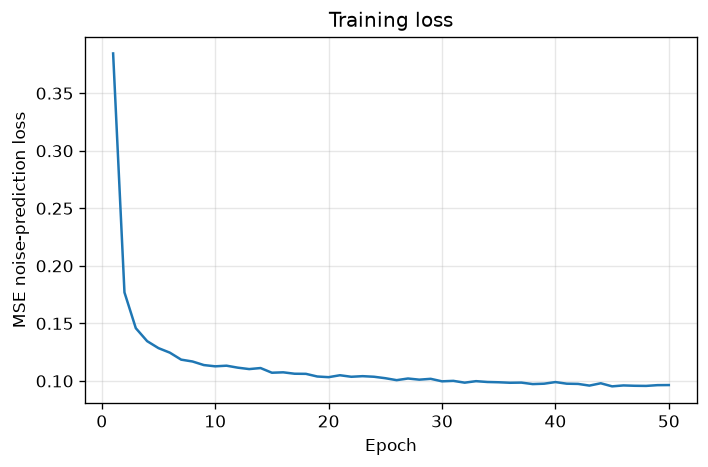

In [5]:
# train the U-Net to predict the noise added to the scaled latent
train_loader = DataLoader(
    TensorDataset(z_train, y_train),
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(SEED),
)

ckpt_path = 'checkpoints/latent_unet.pt'
start_epoch = 0
loss_history = []
if os.path.exists(ckpt_path):
    saved = torch.load(ckpt_path, map_location=device, weights_only=False)
    model.load_state_dict(saved['model'])
    optimizer.load_state_dict(saved['optimizer'])
    loss_history = list(saved['loss_history'])
    start_epoch = len(loss_history)
    print(f'loaded checkpoint, epochs finished: {start_epoch}')
    for i, value in enumerate(loss_history, start=1):
        print(f'epoch {i:02d}/{EPOCHS} loss={value:.6f}')

train_start = time.perf_counter()
for epoch in range(start_epoch, EPOCHS):
    model.train()
    running = 0.0
    seen = 0
    for z0_batch, y in train_loader:
        z0_batch = z0_batch.to(device)
        y = y.to(device)
        t = torch.randint(0, T, (z0_batch.shape[0],), device=device)
        zt, noise = q_sample(z0_batch, t)
        # classifier-free guidance: drop the label to the null class
        drop = torch.rand(y.shape[0], device=device) < LABEL_DROP
        y_in = y.clone()
        y_in[drop] = NULL_LABEL
        pred = model(zt, t, y_in)
        loss = F.mse_loss(pred, noise)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        running += loss.item() * z0_batch.shape[0]
        seen += z0_batch.shape[0]
    epoch_loss = running / seen
    loss_history.append(epoch_loss)
    print(f'epoch {epoch + 1:02d}/{EPOCHS} loss={epoch_loss:.6f}', flush=True)
    torch.save({
        'model': model.state_dict(),
        'optimizer': optimizer.state_dict(),
        'loss_history': loss_history,
    }, ckpt_path)

train_minutes = (time.perf_counter() - train_start) / 60
print(f'training minutes this run: {train_minutes:.2f}')
print(f'epoch 1 loss: {loss_history[0]:.6f}')
print(f'epoch {EPOCHS} loss: {loss_history[-1]:.6f}')

plt.figure(figsize=(6, 4))
plt.plot(range(1, len(loss_history) + 1), loss_history)
plt.xlabel('Epoch')
plt.ylabel('MSE noise-prediction loss')
plt.title('Training loss')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('figures/train_loss.png', dpi=150)
plt.show()


## 5. Sampling with classifier-free guidance

I run the reverse chain for all 1000 steps. At each step I predict the noise twice, once with the class label and once with the null label, and combine them:

ε = (1 + w) ε_cond − w ε_uncond

w = 3. The 64-image grid repeats classes 0–9 in row-major order, so the last four images are classes 0, 1, 2, and 3.

I also decode ten images, one per class, three ways from the same starting noise: unconditional, conditional, and w=3. That is so I can see what the guidance changed, not just the 8×8 grid.


grid labels, row-major: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3]
cfg step 800
cfg step 600
cfg step 400
cfg step 200
cfg step 0
sampling minutes for 64 images: 1.08
uncond step 800
uncond step 600
uncond step 400
uncond step 200
uncond step 0
cond step 800
cond step 600
cond step 400
cond step 200
cond step 0
cfg step 800
cfg step 600
cfg step 400
cfg step 200
cfg step 0


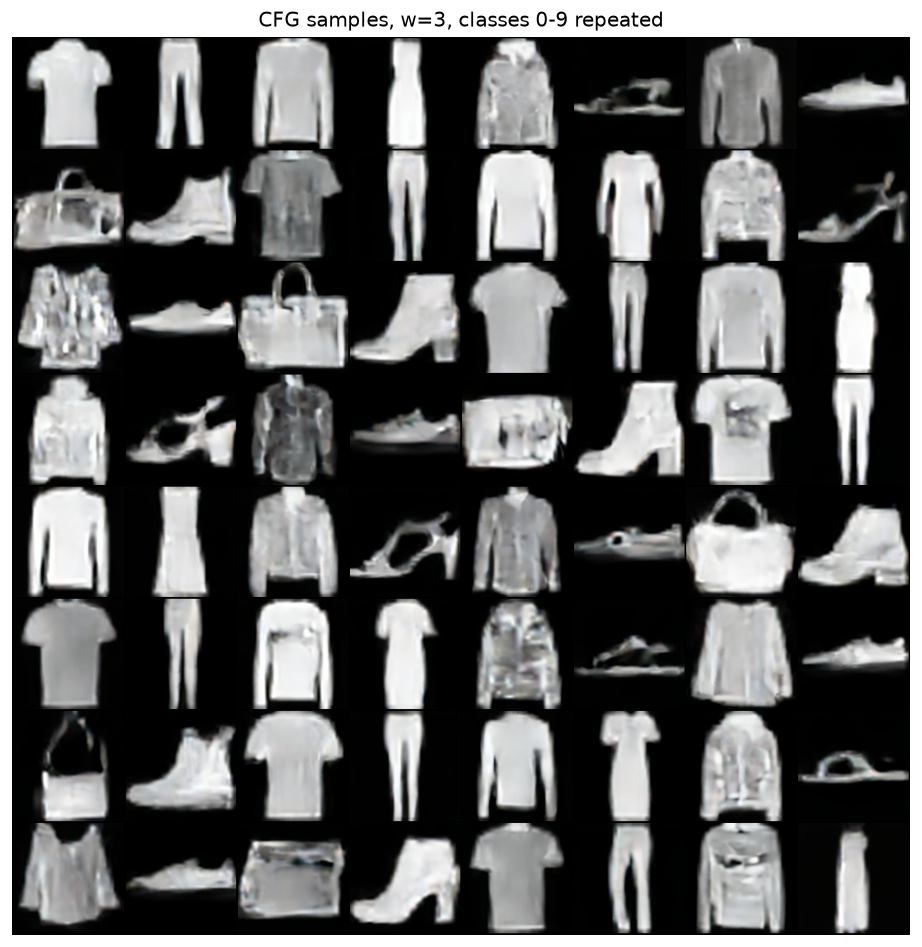

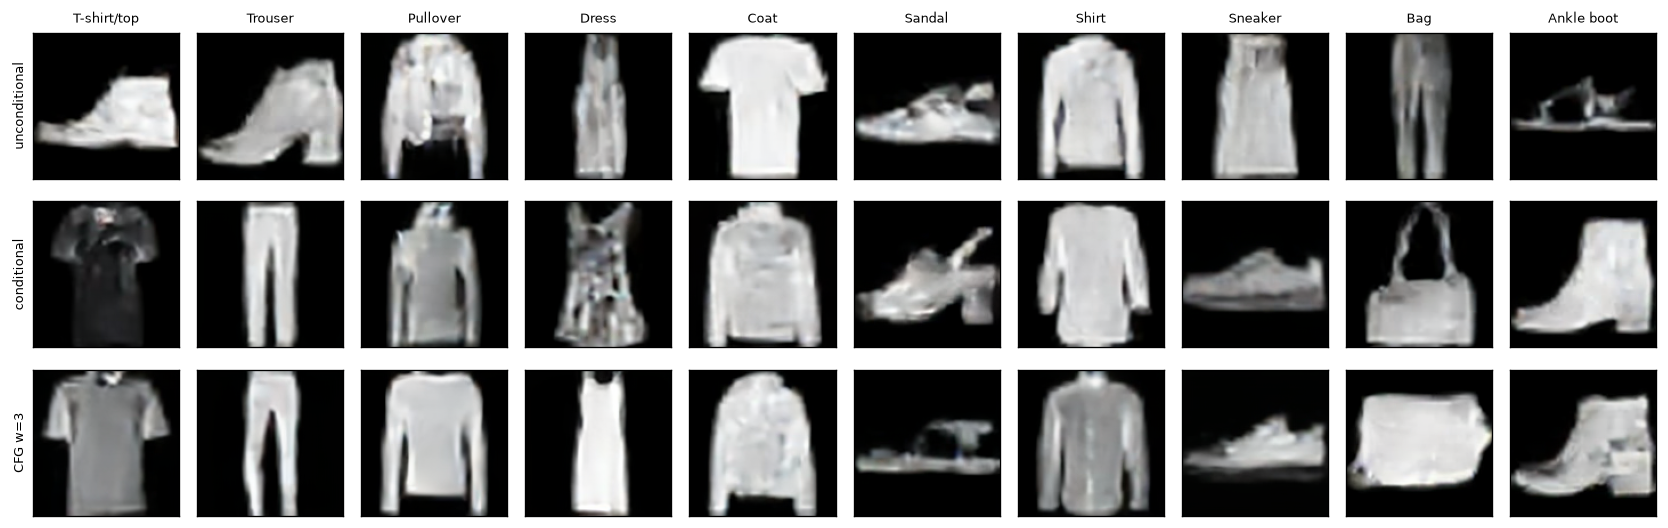

In [6]:
# DDPM reverse step in latent space, then decode with the VAE
@torch.no_grad()
def predict_eps(x, t, labels, mode, w):
    if mode == 'cond':
        return model(x, t, labels)
    if mode == 'uncond':
        return model(x, t, torch.full_like(labels, NULL_LABEL))
    eps_cond, eps_uncond = model(
        torch.cat([x, x], dim=0),
        torch.cat([t, t], dim=0),
        torch.cat([labels, torch.full_like(labels, NULL_LABEL)], dim=0),
    ).chunk(2)
    return (1.0 + w) * eps_cond - w * eps_uncond

@torch.no_grad()
def ddpm_sample(labels, mode='cfg', w=GUIDANCE, x_start=None):
    model.eval()
    n = labels.shape[0]
    x = torch.randn(n, 4, 16, 16, device=device) if x_start is None else x_start.clone()
    for step in reversed(range(T)):
        t = torch.full((n,), step, device=device, dtype=torch.long)
        eps = predict_eps(x, t, labels, mode, w)
        beta_t = betas[step]
        alpha_t = alphas[step]
        alpha_bar_t = alpha_bars[step]
        mean = (x - beta_t / torch.sqrt(1.0 - alpha_bar_t) * eps) / torch.sqrt(alpha_t)
        if step > 0:
            x = mean + torch.sqrt(posterior_variance[step]) * torch.randn_like(x)
        else:
            x = mean
        if step % 200 == 0:
            print(f'{mode} step {step}', flush=True)
    return x

@torch.no_grad()
def decode_latents(z):
    vae.to(device)
    pieces = []
    for i in range(0, z.shape[0], 16):
        decoded = vae.decode(z[i:i + 16] / SCALE).sample
        pieces.append(((decoded + 1) * 0.5).clamp(0, 1).cpu())
    return torch.cat(pieces)

torch.manual_seed(SEED)
labels_64 = (torch.arange(64, device=device) % 10).long()
print('grid labels, row-major:', labels_64.tolist())
sample_start = time.perf_counter()
z_cfg = ddpm_sample(labels_64, mode='cfg', w=GUIDANCE)
cfg_images = decode_latents(z_cfg)
print(f'sampling minutes for 64 images: {(time.perf_counter() - sample_start) / 60:.2f}')

save_image(cfg_images, 'outputs/cfg_grid_w3.png', nrow=8)
plt.figure(figsize=(8, 8))
plt.imshow(make_grid(cfg_images, nrow=8).permute(1, 2, 0).numpy())
plt.title('CFG samples, w=3, classes 0-9 repeated')
plt.axis('off')
plt.tight_layout()
plt.savefig('figures/cfg_samples.png', dpi=150)
plt.show()

# same starting noise, one image per class, three predictions
torch.manual_seed(SEED + 1)
x_start = torch.randn(10, 4, 16, 16, device=device)
labels_10 = torch.arange(10, device=device)
rows = []
for mode in ('uncond', 'cond', 'cfg'):
    z = ddpm_sample(labels_10, mode=mode, w=GUIDANCE, x_start=x_start)
    rows.append(decode_latents(z))

fig, axes = plt.subplots(3, 10, figsize=(14, 4.6))
row_names = ['unconditional', 'conditional', 'CFG w=3']
for r, (images, name) in enumerate(zip(rows, row_names)):
    for c in range(10):
        axes[r, c].imshow(images[c].permute(1, 2, 0).numpy())
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
        if r == 0:
            axes[r, c].set_title(CLASS_NAMES[c], fontsize=8)
    axes[r, 0].set_ylabel(name, fontsize=8)
plt.tight_layout()
plt.savefig('figures/guidance_compare.png', dpi=150)
plt.show()
vae.to('cpu')


## 6. Discussion

The test reconstruction MSE was 0.000781 on all 10,000 test images, measured on the 128×128 encoder inputs in [-1, 1]. In the figure the VAE copies are close to the inputs, and the mark on the pullover is still readable.

The forward figure is the first training image, an ankle boot. It is clear at t=0. At t=200 the boot shape is still there with color noise on it. At t=500 it is mostly gone. At t=800 and t=1000 the decode is colored static. ᾱ at the last step was 4.035827e-05.

The U-Net has 12,289,540 parameters, and the output check printed `torch.Size([2, 4, 16, 16])`. The noise-prediction loss went from 0.384546 in epoch 1 to 0.096441 in epoch 50. It dropped quickly and then flattened near 0.096. Training took 111.44 minutes on MPS.

The 64-image grid uses classes 0–9 repeated in row-major order, with w=3. Most cells look like clothing. Some coats, bags, and sandals are still glassy or mixed, so I am not calling every cell a clean class example. On the comparison figure, which is one shared noise draw, the unconditional row does not follow the column label. The conditional row usually does, and w=3 makes the items simpler. I would not claim more than that from one noise draw.
